# Etapa C — Multiclasse crescente

Orientação do professor: começar com poucas espécies e adicionar uma por vez
(em ordem de número de gravações), para ver **onde** o desempenho degrada. O
modelo segue até as 8 espécies de qualquer forma; o critério abaixo só marca
o ponto de degradação.

**Critério fixado antes de rodar:** degradou quando a espécie recém-adicionada
tem sensibilidade < 70% **ou** a acurácia balanceada cai mais de 5 pontos em
relação ao tamanho anterior (média das sementes, MLP sem peso).

Tudo em treino e validação; o teste continua intocado.

In [1]:
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

dados = np.load("../dados_processados/etapa2.npz", allow_pickle=True)
ctx = pd.read_csv("../dados_processados/contexto_simples.csv")
arq_completa = pd.read_csv("../dados_processados/arquivos_completa.csv")["Arquivo_norm"].to_numpy()

y_simples = dados["y_simples"]
assert (ctx["Espécie/Sonótipo"].to_numpy() == y_simples).all()  # mesma ordem de X_simples

## Mesmas gravações nas duas representações

A completa (25 colunas: 3 pulsos + média + desvio) só existe para gravações
com 3 pulsos. Para comparar simples × completa sem misturar o efeito de
gravações diferentes, as duas usam **as mesmas gravações** (as da completa),
com a divisão treino/validação herdada da Etapa 2. A normalização guardada é
desfeita aqui e refeita a cada tamanho, só com o treino daquele tamanho.

In [2]:
pos_na_completa = {a: i for i, a in enumerate(arq_completa)}
arq_simples = ctx["Arquivo_norm"].to_numpy()

# desfaz a normalização da Etapa 2 (volta às unidades originais)
Xs_bruto = dados["X_simples"] * dados["desvio_simples"] + dados["media_simples"]
Xc_bruto = dados["X_completa"] * dados["desvio_completa"] + dados["media_completa"]
y_completa = dados["y_completa"]


def comuns(pos_simples, pos_completa):
    """Linhas da simples (neste split) que têm par na completa; confere espécie e split."""
    p = np.array([q for q in pos_simples if arq_simples[q] in pos_na_completa])
    idx_c = np.array([pos_na_completa[arq_simples[q]] for q in p])
    assert (y_completa[idx_c] == y_simples[p]).all()
    assert np.isin(idx_c, pos_completa).all()
    return Xs_bruto[p], Xc_bruto[idx_c], y_simples[p]


Xs_tr, Xc_tr, esp_tr = comuns(dados["pos_treino_simples"], dados["pos_treino_completa"])
Xs_va, Xc_va, esp_va = comuns(dados["pos_val_simples"], dados["pos_val_completa"])
print(f"Treino: {len(esp_tr)}   Validação: {len(esp_va)}   Colunas: simples {Xs_tr.shape[1]}, completa {Xc_tr.shape[1]}")

ordem_especies = pd.Series(np.concatenate([esp_tr, esp_va])).value_counts().index.tolist()
print("\nOrdem de entrada (mais gravações primeiro):")
for i, e in enumerate(ordem_especies, 1):
    print(f"  {i}. {e}")

Treino: 8995   Validação: 1932   Colunas: simples 5, completa 25

Ordem de entrada (mais gravações primeiro):
  1. Myotis_lavali
  2. Molossus_molossus
  3. Lasiurus_blossevillii
  4. Neoeptesicus_furinalis
  5. Eumops_sp
  6. Molossus_currentium
  7. Molossops_temminckii
  8. Myotis_nigricans


## Modelo, custo e treino

- **MLP:** `Linear(n_in, 8)` + `Tanh` + `Linear(8, N_L)`, a mesma do A3 com
  N_L saídas. Sem `Softmax` na rede: o `CrossEntropyLoss` do PyTorch aplica a
  softmax internamente (mais estável); a softmax entra só na avaliação.
- **Custo:** entropia cruzada categórica (Slides_5). O slide divide por N_L; o
  PyTorch não. É só um fator constante (equivale a mudar o passo), e sem ele
  o passo efetivo não muda quando N_L cresce.
- **Peso por classe (opcional):** n / (N_L · n_c), calculado no treino (média 1).
- **Treino:** Adam lr 0,01, mini-batch 64, 400 épocas, pesos da época de menor
  perda de validação (mesmo peso na perda de validação).
- **Linear de referência:** regressão softmax (`Linear(n_in, N_L)`), SGD lr 0,1,
  2000 épocas, como o A1 da Etapa B.

In [3]:
def cria_mlp(n_in, n_classes, n_ocultos=8):
    return nn.Sequential(nn.Linear(n_in, n_ocultos), nn.Tanh(), nn.Linear(n_ocultos, n_classes))


def cria_linear(n_in, n_classes):
    return nn.Sequential(nn.Linear(n_in, n_classes))


def pesos_por_classe(y, n_classes):
    n_c = np.bincount(y, minlength=n_classes)
    return len(y) / (n_classes * n_c)


def treina(modelo, otimizador, Xtr, ytr, Xva, yva, pesos=None, n_epocas=400, semente=0):
    torch.manual_seed(semente)
    w = None if pesos is None else torch.tensor(pesos, dtype=torch.float32)
    criterio = nn.CrossEntropyLoss(weight=w)
    tXtr, tytr = torch.from_numpy(Xtr), torch.from_numpy(ytr)
    tXva, tyva = torch.from_numpy(Xva), torch.from_numpy(yva)
    loader = DataLoader(TensorDataset(tXtr, tytr), batch_size=64, shuffle=True)
    melhor, melhores_pesos, melhor_epoca = float("inf"), None, -1
    for epoca in range(n_epocas):
        modelo.train()
        for xb, yb in loader:
            otimizador.zero_grad()
            perda = criterio(modelo(xb), yb)
            perda.backward()
            otimizador.step()
        modelo.eval()
        with torch.no_grad():
            pv = criterio(modelo(tXva), tyva).item()
        if pv < melhor:
            melhor, melhores_pesos, melhor_epoca = pv, copy.deepcopy(modelo.state_dict()), epoca + 1
    modelo.load_state_dict(melhores_pesos)
    return melhor_epoca


def prever(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return torch.softmax(modelo(torch.from_numpy(X)), dim=1).numpy().argmax(axis=1)

## Métricas multiclasse

A partir da matriz de confusão N_L × N_L (linha = previsto, coluna =
verdadeiro, como no Slides_6): sensibilidade e precisão de cada espécie
(tratando-a como positiva e as outras como negativas), acurácia, **acurácia
balanceada** (média das sensibilidades) e **F1 macro** (média dos F1 por
espécie; Grandini et al., 2020). Liberadas pelo professor.

In [4]:
def matriz_confusao(y_real, y_prev, n_classes):
    m = np.zeros((n_classes, n_classes), dtype=int)
    for prev, real in zip(y_prev, y_real):
        m[prev, real] += 1  # linha = previsto, coluna = verdadeiro
    return m


def metricas(m):
    vp = np.diag(m).astype(float)
    sens = vp / m.sum(axis=0)                  # coluna = verdadeiro
    prev_tot = m.sum(axis=1)
    prec = np.divide(vp, prev_tot, out=np.zeros_like(vp), where=prev_tot > 0)
    f1 = np.divide(2 * prec * sens, prec + sens, out=np.zeros_like(vp), where=(prec + sens) > 0)
    return {"acurácia": vp.sum() / m.sum(), "acurácia balanceada": sens.mean(),
            "F1 macro": f1.mean(), "sens": sens, "prec": prec}


# régua da Chave (Etapa 05): centro de FME mais próximo, restrito às espécies do tamanho
CENTROS_CHAVE = {"Eumops_sp": 18.0, "Molossus_currentium": 30.0, "Molossus_molossus": 34.0,
                 "Neoeptesicus_furinalis": 39.0, "Lasiurus_blossevillii": 46.0,
                 "Molossops_temminckii": 50.0, "Myotis_lavali": 50.5, "Myotis_nigricans": 53.5}
COL_FME = 3  # coluna FME na simples (Fmin, Fmax, Bandwidth, FME, Duração)

## A curva crescente

Para cada tamanho N_L de 3 a 8: MLP nas duas representações, sem e com peso,
3 sementes; linear sem peso, 1 semente; régua da Chave. Leva mais de uma hora.
Os resultados agregados são salvos em `dados_processados/` (fora do git).

In [5]:
SEMENTES = [0, 1, 2]
linhas, matrizes = [], {}
t0 = time.time()

for n_esp in range(3, 9):
    especies = ordem_especies[:n_esp]
    cod = {e: i for i, e in enumerate(especies)}
    m_tr, m_va = np.isin(esp_tr, especies), np.isin(esp_va, especies)
    ytr = np.array([cod[e] for e in esp_tr[m_tr]])
    yva = np.array([cod[e] for e in esp_va[m_va]])
    pesos = pesos_por_classe(ytr, n_esp)

    for nome_rep, Xtr_b, Xva_b in [("simples", Xs_tr, Xs_va), ("completa", Xc_tr, Xc_va)]:
        Xtr, Xva = Xtr_b[m_tr], Xva_b[m_va]
        media, desvio = Xtr.mean(axis=0), Xtr.std(axis=0)  # normalização só no treino deste tamanho
        Xtr = ((Xtr - media) / desvio).astype(np.float32)
        Xva = ((Xva - media) / desvio).astype(np.float32)

        rodadas = [("MLP", peso, s) for peso in ["sem peso", "com peso"] for s in SEMENTES] + [("linear", "sem peso", 0)]
        for modelo_nome, peso, s in rodadas:
            torch.manual_seed(s)
            if modelo_nome == "MLP":
                modelo = cria_mlp(Xtr.shape[1], n_esp)
                otim, n_ep = torch.optim.Adam(modelo.parameters(), lr=0.01), 400
            else:
                modelo = cria_linear(Xtr.shape[1], n_esp)
                otim, n_ep = torch.optim.SGD(modelo.parameters(), lr=0.1), 2000
            ep = treina(modelo, otim, Xtr, ytr, Xva, yva,
                        pesos=pesos if peso == "com peso" else None, n_epocas=n_ep, semente=s)
            m = matriz_confusao(yva, prever(modelo, Xva), n_esp)
            met = metricas(m)
            matrizes[(n_esp, nome_rep, modelo_nome, peso, s)] = m
            linhas.append({"n espécies": n_esp, "representação": nome_rep, "modelo": modelo_nome,
                           "peso": peso, "semente": s, "melhor época": ep, "épocas": n_ep,
                           **{k: met[k] for k in ["acurácia", "acurácia balanceada", "F1 macro"]},
                           "sens nova espécie": met["sens"][-1],
                           **{f"sens {e}": v for e, v in zip(especies, met["sens"])},
                           **{f"prec {e}": v for e, v in zip(especies, met["prec"])}})

    # régua da Chave neste tamanho (sem aprendizado)
    fme_va = Xs_va[m_va][:, COL_FME]
    centros = np.array([CENTROS_CHAVE[e] for e in especies])
    prev_r = np.argmin(np.abs(fme_va[:, None] - centros[None, :]), axis=1)
    met = metricas(matriz_confusao(yva, prev_r, n_esp))
    linhas.append({"n espécies": n_esp, "representação": "FME", "modelo": "régua da Chave", "peso": "-",
                   "semente": -1, **{k: met[k] for k in ["acurácia", "acurácia balanceada", "F1 macro"]},
                   "sens nova espécie": met["sens"][-1]})
    print(f"{n_esp} espécies prontas ({(time.time() - t0) / 60:.0f} min)")

res = pd.DataFrame(linhas)
res.to_csv("../dados_processados/etapa_c_resultados.csv", index=False)
np.savez("../dados_processados/etapa_c_matrizes.npz",
         **{"|".join(map(str, k)): v for k, v in matrizes.items()})

3 espécies prontas (16 min)


4 espécies prontas (34 min)


5 espécies prontas (53 min)


6 espécies prontas (72 min)


7 espécies prontas (93 min)


8 espécies prontas (114 min)


## Convergência

Se a melhor época cair perto da última, o treino ainda não tinha terminado e o
resultado pode estar subestimado.

In [6]:
conv = res[res["modelo"] != "régua da Chave"].copy()
conv["fração"] = conv["melhor época"] / conv["épocas"]
print("Rodadas com melhor época nos últimos 10% das épocas:")
print(conv[conv["fração"] > 0.9][["n espécies", "representação", "modelo", "peso", "semente", "melhor época", "épocas"]]
      .to_string(index=False) if (conv["fração"] > 0.9).any() else "  nenhuma")

Rodadas com melhor época nos últimos 10% das épocas:
 n espécies representação modelo     peso  semente  melhor época  épocas
          4       simples    MLP com peso        2         381.0   400.0
          5       simples    MLP sem peso        2         397.0   400.0
          5       simples    MLP com peso        1         380.0   400.0
          5       simples    MLP com peso        2         385.0   400.0
          6       simples    MLP sem peso        0         365.0   400.0
          6       simples    MLP sem peso        1         400.0   400.0
          6       simples    MLP com peso        0         365.0   400.0
          6      completa linear sem peso        0        1950.0  2000.0
          7      completa linear sem peso        0        1809.0  2000.0
          8       simples    MLP sem peso        0         390.0   400.0
          8       simples    MLP com peso        2         394.0   400.0
          8      completa linear sem peso        0        1876.0  2000.

## Resultado: acurácia balanceada × número de espécies

In [7]:
resumo = (res.groupby(["n espécies", "modelo", "representação", "peso"])
            [["acurácia balanceada", "F1 macro", "acurácia", "sens nova espécie"]]
            .agg(["mean", "std"]).round(3))
resumo

acurácia balanceada         \
                                                                mean    std   
n espécies modelo         representação peso                                  
3          MLP            completa      com peso               0.991  0.000   
                                        sem peso               0.991  0.001   
                          simples       com peso               0.992  0.001   
                                        sem peso               0.993  0.000   
           linear         completa      sem peso               0.958    NaN   
                          simples       sem peso               0.948    NaN   
           régua da Chave FME           -                      0.845    NaN   
4          MLP            completa      com peso               0.974  0.002   
                                        sem peso               0.970  0.005   
                          simples       com peso               0.975  0.000   
                                        sem peso               0.975  0.001   
           linear         completa      sem peso               0.923    NaN   
                          simples       sem peso               0.911    NaN   
           régua da Chave FME           -                      0.817    NaN   
5          MLP            completa      com peso               0.979  0.003   
                                        sem peso               0.978  0.004   
                          simples       com peso               0.977  0.003   
                                        sem peso               0.979  0.002   
           linear         completa      sem peso               0.943    NaN   
                          simples       sem peso               0.930    NaN   
           régua da Chave FME           -                      0.854    NaN   
6          MLP            completa      com peso               0.964  0.004   
                                        sem peso               0.965  0.001   
                          simples       com peso               0.969  0.002   
                                        sem peso               0.961  0.005   
           linear         completa      sem peso               0.919    NaN   
                          simples       sem peso               0.924    NaN   
           régua da Chave FME           -                      0.791    NaN   
7          MLP            completa      com peso               0.966  0.005   
                                        sem peso               0.962  0.002   
                          simples       com peso               0.973  0.002   
                                        sem peso               0.962  0.004   
           linear         completa      sem peso               0.928    NaN   
                          simples       sem peso               0.927    NaN   
           régua da Chave FME           -                      0.665    NaN   
8          MLP            completa      com peso               0.965  0.002   
                                        sem peso               0.949  0.003   
                          simples       com peso               0.969  0.004   
                                        sem peso               0.947  0.001   
           linear         completa      sem peso               0.926    NaN   
                          simples       sem peso               0.914    NaN   
           régua da Chave FME           -                      0.696    NaN   

                                                 F1 macro        acurácia  \
                                                     mean    std     mean   
n espécies modelo         representação peso                                
3          MLP            completa      com peso    0.991  0.001    0.994   
                                        sem peso    0.992  0.001    0.995   
                          simples       com peso    0.991  0.002    0.994   
                               

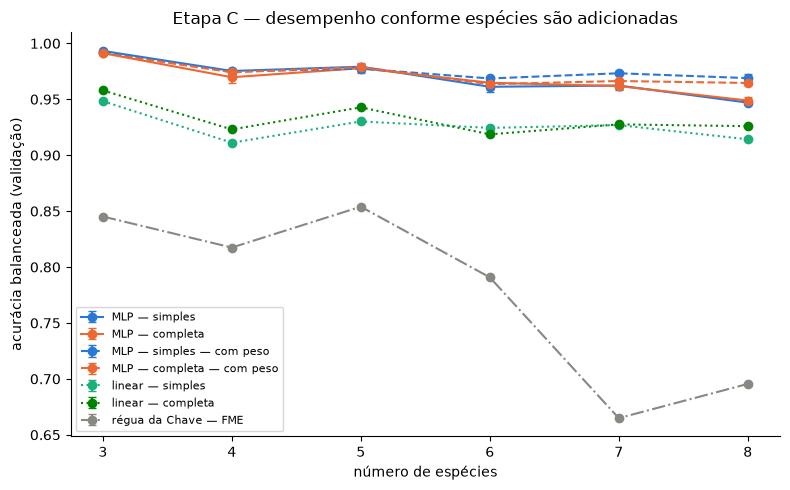

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
estilos = [("MLP", "simples", "sem peso", "#2a78d6", "-"), ("MLP", "completa", "sem peso", "#eb6834", "-"),
           ("MLP", "simples", "com peso", "#2a78d6", "--"), ("MLP", "completa", "com peso", "#eb6834", "--"),
           ("linear", "simples", "sem peso", "#1baf7a", ":"), ("linear", "completa", "sem peso", "#008300", ":"),
           ("régua da Chave", "FME", "-", "#898781", "-.")]
for modelo, rep_, peso, cor, traco in estilos:
    g = res[(res["modelo"] == modelo) & (res["representação"] == rep_) & (res["peso"] == peso)]
    g = g.groupby("n espécies")["acurácia balanceada"].agg(["mean", "std"]).fillna(0)
    ax.errorbar(g.index, g["mean"], yerr=g["std"], color=cor, linestyle=traco, marker="o", capsize=3,
                label=f"{modelo} — {rep_}" + ("" if peso in ("-", "sem peso") else " — com peso"))
ax.set_xlabel("número de espécies")
ax.set_ylabel("acurácia balanceada (validação)")
ax.set_title("Etapa C — desempenho conforme espécies são adicionadas")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Onde degrada (critério fixado antes)

Aplicado à MLP sem peso, média das 3 sementes, em cada representação.

In [9]:
for rep_ in ["simples", "completa"]:
    g = (res[(res["modelo"] == "MLP") & (res["representação"] == rep_) & (res["peso"] == "sem peso")]
         .groupby("n espécies")[["acurácia balanceada", "sens nova espécie"]].mean())
    print(f"\n{rep_}:")
    anterior = None
    for n, linha in g.iterrows():
        motivos = []
        if linha["sens nova espécie"] < 0.70:
            motivos.append(f"sensibilidade da nova espécie {linha['sens nova espécie']:.3f} < 0,70")
        if anterior is not None and anterior - linha["acurácia balanceada"] > 0.05:
            motivos.append(f"queda de {100 * (anterior - linha['acurácia balanceada']):.1f} pontos")
        print(f"  {n} espécies ({ordem_especies[n - 1]}): acurácia balanceada {linha['acurácia balanceada']:.3f}"
              + ("  <-- DEGRADOU: " + "; ".join(motivos) if motivos else ""))
        anterior = linha["acurácia balanceada"]


simples:
  3 espécies (Lasiurus_blossevillii): acurácia balanceada 0.993
  4 espécies (Neoeptesicus_furinalis): acurácia balanceada 0.975
  5 espécies (Eumops_sp): acurácia balanceada 0.979
  6 espécies (Molossus_currentium): acurácia balanceada 0.961
  7 espécies (Molossops_temminckii): acurácia balanceada 0.962
  8 espécies (Myotis_nigricans): acurácia balanceada 0.947

completa:
  3 espécies (Lasiurus_blossevillii): acurácia balanceada 0.991
  4 espécies (Neoeptesicus_furinalis): acurácia balanceada 0.970
  5 espécies (Eumops_sp): acurácia balanceada 0.978
  6 espécies (Molossus_currentium): acurácia balanceada 0.965
  7 espécies (Molossops_temminckii): acurácia balanceada 0.962
  8 espécies (Myotis_nigricans): acurácia balanceada 0.949


## Sensibilidade de cada espécie com as 8

Média das 3 sementes, MLP.

In [10]:
g8 = res[(res["n espécies"] == 8) & (res["modelo"] == "MLP")]
cols = [f"sens {e}" for e in ordem_especies]
tab = g8.groupby(["representação", "peso"])[cols].mean().T.round(3)
tab.index = [c.replace("sens ", "") for c in tab.index]
tab

representação          completa           simples         
peso                   com peso sem peso com peso sem peso
Myotis_lavali             0.949    0.988    0.946    0.987
Molossus_molossus         0.915    0.949    0.934    0.951
Lasiurus_blossevillii     0.975    0.975    0.977    0.973
Neoeptesicus_furinalis    0.938    0.935    0.938    0.938
Eumops_sp                 1.000    0.997    0.994    0.997
Molossus_currentium       0.951    0.892    0.979    0.913
Molossops_temminckii      1.000    0.978    0.996    0.982
Myotis_nigricans          0.988    0.877    0.988    0.836

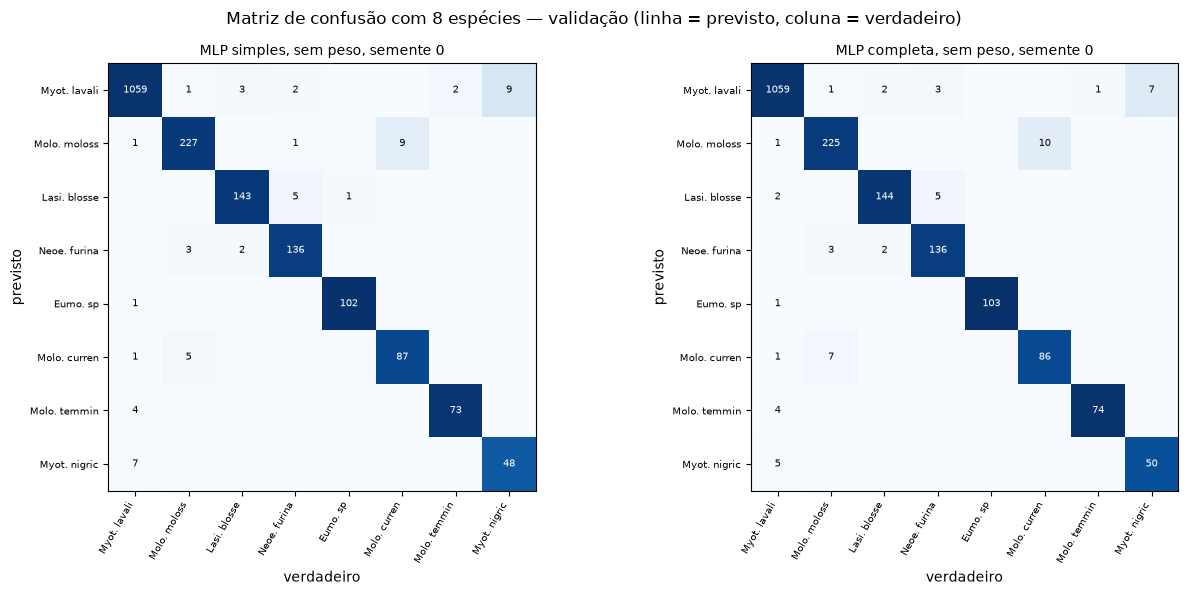

In [11]:
def plota_matriz(ax, m, nomes, titulo):
    frac = m / m.sum(axis=0, keepdims=True)  # fração de cada espécie verdadeira (coluna)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(nomes)):
        for j in range(len(nomes)):
            if m[i, j]:
                ax.text(j, i, m[i, j], ha="center", va="center", fontsize=7,
                        color="white" if frac[i, j] > 0.5 else "black")
    curtos = [n.split("_")[0][:4] + ". " + n.split("_")[1][:6] for n in nomes]
    ax.set_xticks(range(len(nomes)), curtos, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(nomes)), curtos, fontsize=7)
    ax.set_xlabel("verdadeiro")
    ax.set_ylabel("previsto")
    ax.set_title(titulo, fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, rep_ in zip(axes, ["simples", "completa"]):
    plota_matriz(ax, matrizes[(8, rep_, "MLP", "sem peso", 0)], ordem_especies, f"MLP {rep_}, sem peso, semente 0")
fig.suptitle("Matriz de confusão com 8 espécies — validação (linha = previsto, coluna = verdadeiro)")
fig.tight_layout()
plt.show()